# 02 · Análisis exploratorio de `clientes` (y sus pedidos)

Exploración con **pandas + matplotlib** de la tabla `clientes` y de su relación con `pedidos`, `detalle_pedidos` y `productos`.

> ⚠️ Los datos de la tienda son **sintéticos y deterministas** (los genera `init.sql` con fórmulas, sin `random()`). Este notebook demuestra el método de análisis; las cifras no describen ningún negocio real.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from sqlalchemy import text

from src.config import get_engine
from src.queries import get_query

pd.set_option("display.max_columns", None)
plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False})

engine = get_engine()

def consulta(nombre, **params):
    return pd.read_sql(text(get_query(nombre)), engine, params=params)

## 1. Estructura y calidad de los datos

In [2]:
clientes = pd.read_sql("SELECT * FROM clientes ORDER BY id", engine, parse_dates=["fecha_registro"])
clientes.info()
clientes.head()

<class 'pandas.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype        
---  ------          --------------  -----        
 0   id              50 non-null     int64        
 1   nombre          50 non-null     str          
 2   email           50 non-null     str          
 3   ciudad          50 non-null     str          
 4   comunidad       50 non-null     str          
 5   fecha_registro  50 non-null     datetime64[s]
dtypes: datetime64[s](1), int64(1), str(4)
memory usage: 2.5 KB


,id,nombre,email,ciudad,comunidad,fecha_registro
0,1,Ana García,ana.garcia@ejemplo.com,Madrid,Comunidad de Madrid,2024-01-18
1,2,Carlos López,carlos.lopez@ejemplo.com,Barcelona,Cataluña,2024-02-04
2,3,María Fernández,maria.fernandez@ejemplo.com,Valencia,Comunidad Valenciana,2024-02-21
3,4,Javier Martínez,javier.martinez@ejemplo.com,Sevilla,Andalucía,2024-03-09
4,5,Laura Sánchez,laura.sanchez@ejemplo.com,Bilbao,País Vasco,2024-03-26


In [3]:
print("Nulos por columna:")
print(clientes.isna().sum().to_string())
print("\nEmails duplicados:", clientes["email"].duplicated().sum())
print("Ciudades distintas:", clientes["ciudad"].nunique(), "| Comunidades:", clientes["comunidad"].nunique())
print("Rango de altas:", clientes["fecha_registro"].min().date(), "→", clientes["fecha_registro"].max().date())

Nulos por columna:
id                0
nombre            0
email             0
ciudad            0
comunidad         0
fecha_registro    0

Emails duplicados: 0
Ciudades distintas: 50 | Comunidades: 19
Rango de altas: 2024-01-05 → 2025-06-11


## 2. ¿Dónde están los clientes?

comunidad
Andalucía             8
Canarias              7
Castilla y León       7
Castilla-La Mancha    4
Cataluña              3
Name: count, dtype: int64

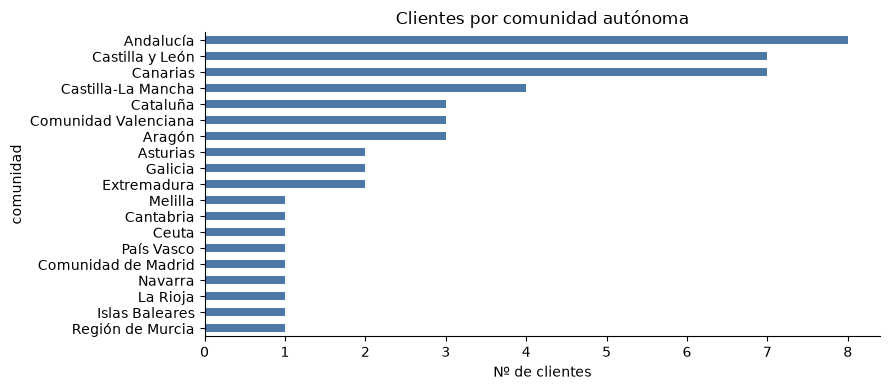

In [4]:
por_comunidad = clientes["comunidad"].value_counts().sort_values()
ax = por_comunidad.plot.barh(color="#4C78A8")
ax.set_title("Clientes por comunidad autónoma")
ax.set_xlabel("Nº de clientes")
plt.tight_layout()
por_comunidad.sort_values(ascending=False).head(5)

## 3. Evolución de las altas

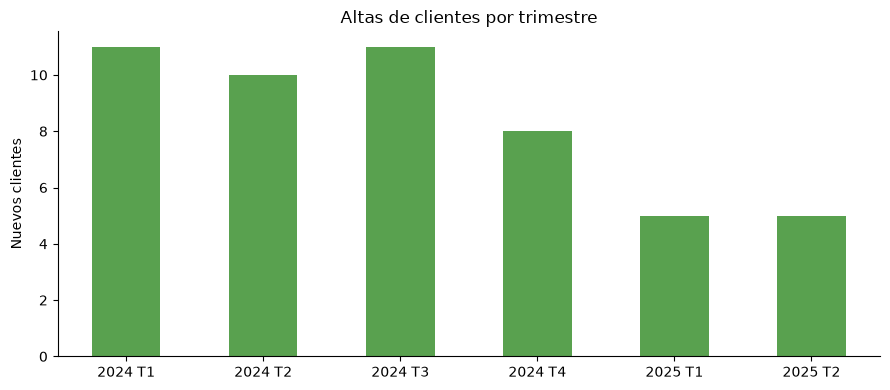

In [5]:
altas = clientes.set_index("fecha_registro").resample("QS").size()
ax = altas.plot.bar(color="#59A14F")
ax.set_xticklabels([f"{d.year} T{(d.month - 1) // 3 + 1}" for d in altas.index], rotation=0)
ax.set_title("Altas de clientes por trimestre")
ax.set_xlabel("")
ax.set_ylabel("Nuevos clientes")
plt.tight_layout()

## 4. Clientes y pedidos (relaciones con `JOIN`)

Las consultas están en `sql/analytics.sql` y se cargan por nombre.

In [6]:
sin_pedidos = consulta("clientes_sin_pedidos")
print(f"{len(sin_pedidos)} de {len(clientes)} clientes ({len(sin_pedidos) / len(clientes):.0%}) no han comprado nunca")
sin_pedidos.head()

10 de 50 clientes (20%) no han comprado nunca


,id,nombre,ciudad,comunidad,fecha_registro
0,5,Laura Sánchez,Bilbao,País Vasco,2024-03-26
1,10,Daniel Moreno,Palma,Islas Baleares,2024-06-19
2,15,Paula Navarro,Gijón,Asturias,2024-09-12
3,20,Fernando Ramírez,Salamanca,Castilla y León,2024-12-06
4,25,Isabel Blanco,Burgos,Castilla y León,2025-03-01


count      40.00
mean     1587.24
std       809.83
min        34.50
25%       821.40
50%      1582.80
75%      2066.70
max      2933.45
Name: gasto, dtype: float64

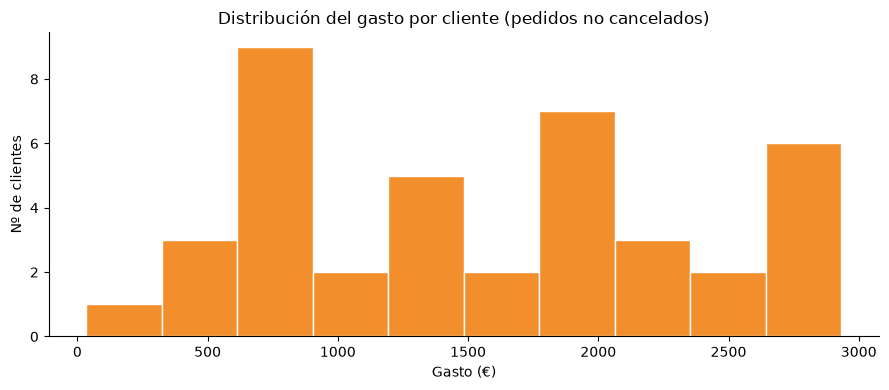

In [7]:
gasto = consulta("top_clientes", limite=len(clientes))   # todos los clientes con compras
ax = gasto["gasto"].plot.hist(bins=10, color="#F28E2B", edgecolor="white")
ax.set_title("Distribución del gasto por cliente (pedidos no cancelados)")
ax.set_xlabel("Gasto (€)")
ax.set_ylabel("Nº de clientes")
plt.tight_layout()
gasto["gasto"].describe().round(2)

In [8]:
consulta("top_clientes", limite=5)

,ranking,nombre,comunidad,pedidos,gasto
0,1,Rubén Suárez,Asturias,3,2933.45
1,2,Irene Herrera,Canarias,3,2853.60
2,2,Marta Romero,Castilla y León,3,2853.60
3,4,Eva Ferrer,Cataluña,3,2848.20
4,4,Sara Ramos,Castilla-La Mancha,3,2848.20


## 5. Ingresos por categoría y por mes

,categoria,unidades,ingresos,porcentaje
0,Informática,107,37908.2,59.7
1,Hogar,132,17864.0,28.1
2,Deporte,116,4971.7,7.8
3,Libros,90,2745.8,4.3


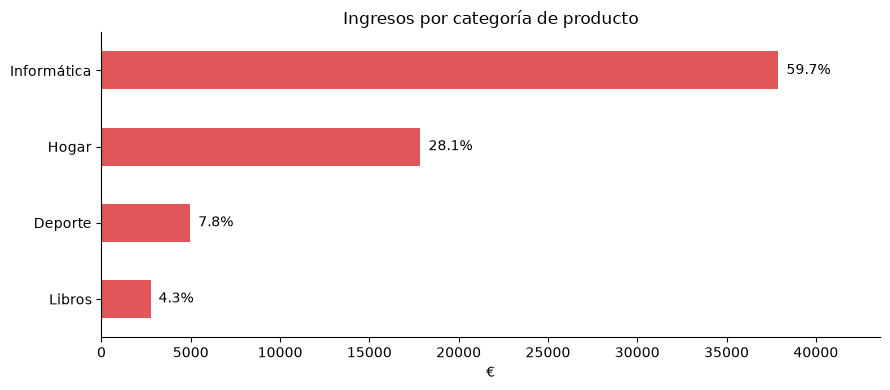

In [9]:
cat = consulta("ingresos_por_categoria")
ax = cat.set_index("categoria")["ingresos"].sort_values().plot.barh(color="#E15759")
for i, (ingresos, pct) in enumerate(zip(cat.sort_values("ingresos")["ingresos"], cat.sort_values("ingresos")["porcentaje"])):
    ax.text(ingresos, i, f"  {pct:.1f}%", va="center")
ax.set_title("Ingresos por categoría de producto")
ax.set_xlabel("€")
ax.set_ylabel("")
ax.margins(x=0.15)
plt.tight_layout()
cat

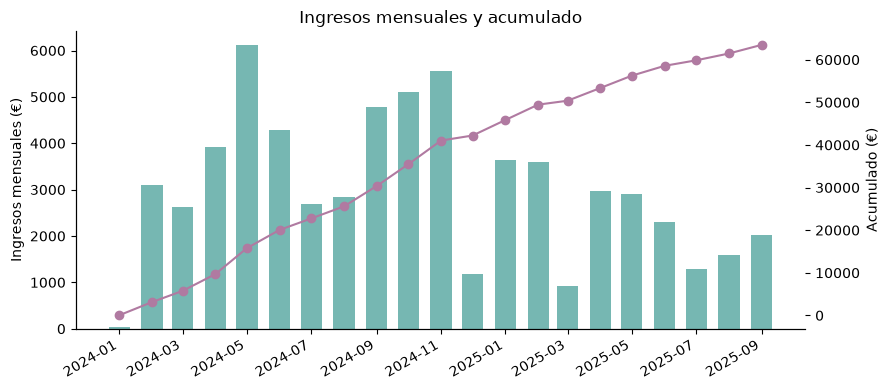

In [10]:
mensual = consulta("gasto_acumulado_mensual").set_index("mes")
fig, ax = plt.subplots()
ax.bar(mensual.index, mensual["ingresos"], width=20, color="#76B7B2", label="Ingresos del mes")
ax.set_ylabel("Ingresos mensuales (€)")
ax2 = ax.twinx()
ax2.plot(mensual.index, mensual["acumulado"], color="#B07AA1", marker="o", label="Acumulado")
ax2.set_ylabel("Acumulado (€)")
ax.set_title("Ingresos mensuales y acumulado")
fig.autofmt_xdate()
plt.tight_layout()

In [11]:
consulta("ticket_medio_por_comunidad").head(8)

,comunidad,pedidos,ticket_medio
0,Comunidad de Madrid,1,2026.80
1,Melilla,2,988.05
2,Asturias,3,977.82
3,Castilla-La Mancha,6,963.61
4,Extremadura,3,949.40
5,Cantabria,3,781.57
6,La Rioja,2,734.65
7,Cataluña,5,733.92


## Conclusiones

- **Calidad de datos:** sin nulos, sin emails duplicados, una ciudad distinta por cliente y una comunidad asignada a todos.
- **Distribución geográfica:** Andalucía (8), Canarias (7) y Castilla y León (7) concentran más clientes; el resto de comunidades tiene 4 o menos.
- **Clientes sin compras:** 10 de 50 (20 %). Es una consecuencia del generador (los clientes con `id` múltiplo de 5 no tienen pedidos), útil aquí para demostrar `LEFT JOIN … IS NULL`.
- **Ingresos:** Informática aporta ~60 % de los ingresos y Hogar ~28 %, mientras que Deporte y Libros suman ~12 % (ver tabla de la sección 5). Con 12 productos, el peso lo marca el precio unitario de cada categoría.
- **Ticket medio por comunidad:** con 1–3 pedidos por comunidad, el ranking de la última tabla **no es estadísticamente fiable**; se muestra para ilustrar la agregación, no para sacar conclusiones.

Siguiente paso: [`03_marketing_bancario.ipynb`](03_marketing_bancario.ipynb), con datos reales (45.211 contactos) cargados por el ETL.